In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Change this path to the location of your downloaded CSV file
df = pd.read_csv(r"C:\Users\maniv\Downloads\gwq_chemical_parameter_manual_cgwb_ap_1961_2025.csv")

print("Original dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
display(df.head())

Original dataset shape: (10950, 46)

Column names:
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Potential of Hydrogen (pH)', 'Electric Conductivity (μS/cm)', 'Total Dissolved Solids (mg/L)', 'Carbonate (mg/L)', 'Bicarbonate (mg/L)', 'Total Alkalinity (mg/L as CaCO3)', 'Chloride (mg/L)', 'Nitrate N (mgN/L)', 'Sulphate (mg/L)', 'Phosphate(mg/L)', 'Silica(mg/L)', 'Fluoride (mg/L)', 'Total Hardness (mgCaCO3/L)', 'Calcium (mg/L)', 'Magnesium (mg/L)', 'Sodium (mg/L)', 'Potassium (mg/L)', 'Iron(mg/L)', 'Arsenic (mg/L)', 'Uranium(mg/L)', 'Manganese (mg/L)', 'Copper (mg/L)', 'Lead (mg/L)', 'Zinc (mg/L)', 'Nickel (mg/L)', 'Cadmium (mg/L)', 'Chromium (mg/L)']


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,...,Iron(mg/L),Arsenic (mg/L),Uranium(mg/L),Manganese (mg/L),Copper (mg/L),Lead (mg/L),Zinc (mg/L),Nickel (mg/L),Cadmium (mg/L),Chromium (mg/L)
0,1,Addanki,CGWB,28,Andhra Pradesh,517,PRAKASAM,ADDANKI,ADDANKI,Addanki,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Addanki-new,CGWB,28,Andhra Pradesh,517,PRAKASAM,ADDANKI,ADDANKI,Addanki-new,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Addanki-new,CGWB,28,Andhra Pradesh,517,PRAKASAM,ADDANKI,ADDANKI,Addanki-new,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Addanki-new,CGWB,28,Andhra Pradesh,517,PRAKASAM,ADDANKI,ADDANKI,Addanki-new,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Addanki-new,CGWB,28,Andhra Pradesh,517,PRAKASAM,ADDANKI,ADDANKI,Addanki-new,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
cols_to_use = {
    'Potential of Hydrogen (pH)': 'ph',
    'Electric Conductivity (μS/cm)': 'ec',
    'Carbonate (mg/L)': 'carbonate',
    'Bicarbonate (mg/L)': 'bicarbonate',
    'Total Alkalinity (mg/L as CaCO3)': 'alkalinity',
    'Chloride (mg/L)': 'chloride',
    'Sulphate (mg/L)': 'sulphate',
    'Total Hardness (mgCaCO3/L)': 'hardness',
    'Calcium (mg/L)': 'calcium',
    'Magnesium (mg/L)': 'magnesium',
    'Sodium (mg/L)': 'sodium'
}

data = df[list(cols_to_use.keys())].rename(columns=cols_to_use).copy()
data["district"] = df.loc[data.index, "District"].fillna("Unknown").astype(str)

print("Selected dataset shape:", data.shape)
display(data.head())

Selected dataset shape: (10950, 12)


,ph,ec,carbonate,bicarbonate,alkalinity,chloride,sulphate,hardness,calcium,magnesium,sodium,district
0,8.31,1540.0,NaN,NaN,NaN,145.0,NaN,NaN,NaN,NaN,NaN,PRAKASAM
1,8.68,690.0,6.0,220.0,NaN,74.0,14.0,220.0,20.0,41.0,51.0,PRAKASAM
2,10.45,1440.0,NaN,NaN,NaN,258.0,NaN,NaN,NaN,NaN,NaN,PRAKASAM
3,7.97,1980.0,NaN,NaN,NaN,433.0,NaN,NaN,NaN,NaN,NaN,PRAKASAM
4,7.51,1960.0,NaN,458.0,375.4,333.0,110.0,741.0,132.0,100.0,167.0,PRAKASAM


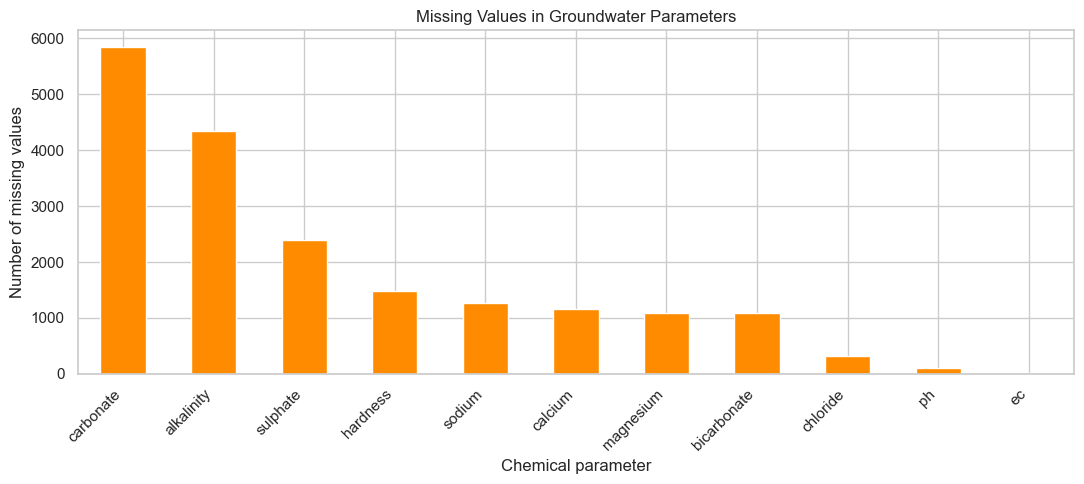

,Missing values
carbonate,5848
alkalinity,4348
sulphate,2385
hardness,1482
sodium,1264
calcium,1159
magnesium,1093
bicarbonate,1092
chloride,318
ph,111


In [3]:
missing_count = data.drop(columns="district").isnull().sum().sort_values(ascending=False)

plt.figure(figsize=(11, 5))
missing_count.plot(kind="bar", color="darkorange")
plt.title("Missing Values in Groundwater Parameters")
plt.xlabel("Chemical parameter")
plt.ylabel("Number of missing values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(missing_count.to_frame("Missing values"))

In [4]:
numeric_columns = [
    "ph", "ec", "carbonate", "bicarbonate", "alkalinity",
    "chloride", "sulphate", "hardness", "calcium",
    "magnesium", "sodium"
]

# Replace physically invalid negative measurements with missing values
data[numeric_columns] = data[numeric_columns].mask(data[numeric_columns] < 0)

# Remove impossible pH readings
data = data[(data["ph"].isna()) | ((data["ph"] >= 0) & (data["ph"] <= 14))].copy()

# Fill missing values using the median of each parameter
data[numeric_columns] = data[numeric_columns].fillna(data[numeric_columns].median())

print("Missing numeric values after cleaning:", data[numeric_columns].isnull().sum().sum())
print("Cleaned dataset shape:", data.shape)
display(data[numeric_columns].describe().T)

Missing numeric values after cleaning: 0
Cleaned dataset shape: (10950, 12)


,count,mean,std,min,25%,50%,75%,max
ph,10950.0,7.939262,0.443254,5.15,7.66,7.91,8.200,11.13
ec,10950.0,1770.014262,1674.660950,9.87,815.00,1296.50,2180.000,40000.00
carbonate,10950.0,4.081998,15.815709,0.00,0.00,0.00,0.000,252.00
bicarbonate,10950.0,360.650538,206.092784,0.00,220.00,329.00,456.375,2837.00
alkalinity,10950.0,292.778032,133.870307,0.00,245.10,280.25,309.840,1839.70
chloride,10950.0,280.960174,407.834678,3.50,75.00,160.00,333.000,7374.00
sulphate,10950.0,106.225970,184.844023,0.00,34.00,62.00,106.000,4600.00
hardness,10950.0,396.657724,328.134869,0.00,230.00,320.00,450.000,6800.00
calcium,10950.0,72.553904,64.496236,1.60,36.00,56.00,86.000,1208.00
magnesium,10950.0,54.145488,55.600136,0.00,25.55,40.00,63.000,1034.55


In [5]:
data["is_potable"] = (
    (data["ph"] >= 6.5) & (data["ph"] <= 8.5) &
    (data["hardness"] <= 600) &
    (data["chloride"] <= 1000) &
    (data["sulphate"] <= 400) &
    (data["ec"] <= 2250)
).astype(int)

print("Screening label counts:")
display(data["is_potable"].value_counts().rename(index={0: "Does not pass screening", 1: "Passes screening"}))

print("\nScreening label percentage:")
display((data["is_potable"].value_counts(normalize=True) * 100).round(2))

Screening label counts:


is_potable
Passes screening           7260
Does not pass screening    3690
Name: count, dtype: int64


Screening label percentage:


is_potable
1    66.3
0    33.7
Name: proportion, dtype: float64

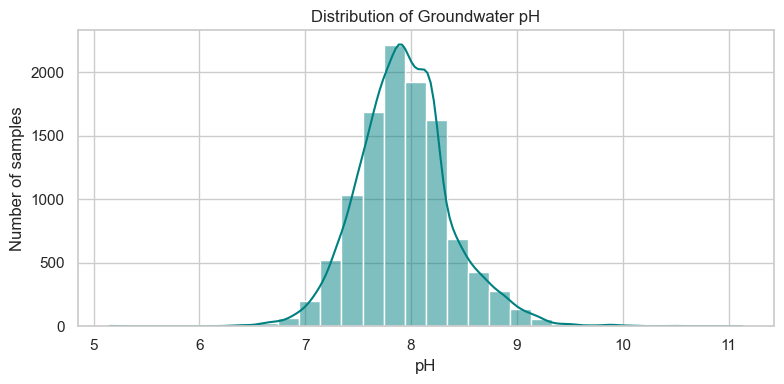

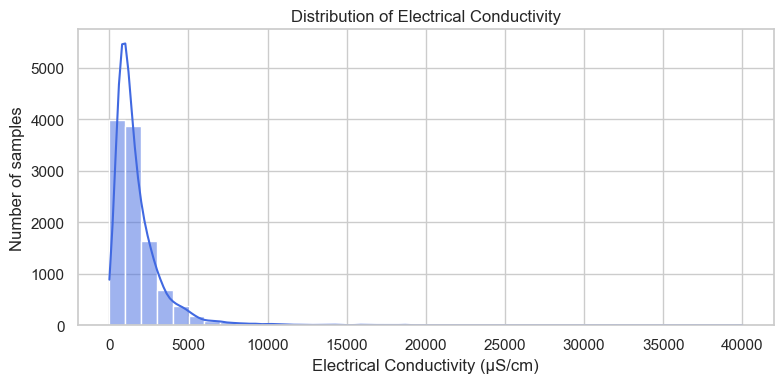

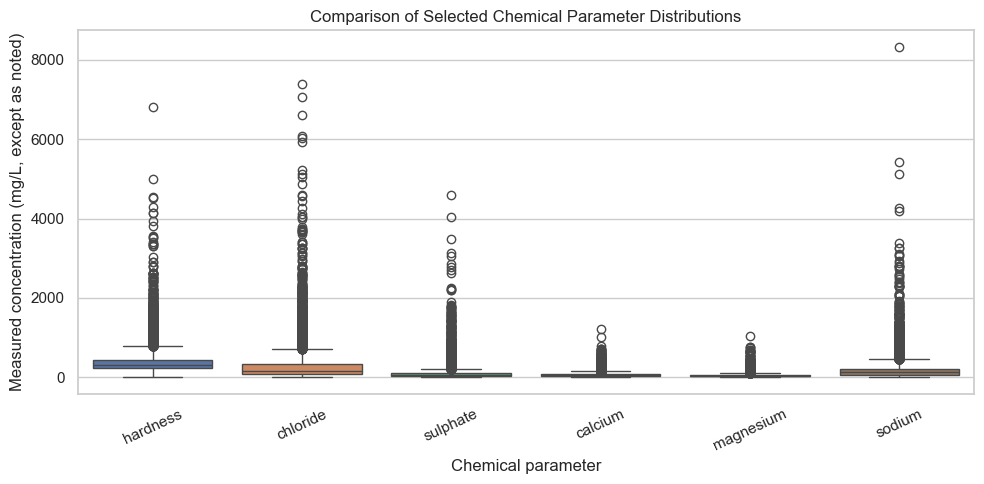

In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="ph", bins=30, kde=True, color="teal")
plt.title("Distribution of Groundwater pH")
plt.xlabel("pH")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="ec", bins=40, kde=True, color="royalblue")
plt.title("Distribution of Electrical Conductivity")
plt.xlabel("Electrical Conductivity (μS/cm)")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=data[["hardness", "chloride", "sulphate", "calcium", "magnesium", "sodium"]])
plt.title("Comparison of Selected Chemical Parameter Distributions")
plt.xlabel("Chemical parameter")
plt.ylabel("Measured concentration (mg/L, except as noted)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

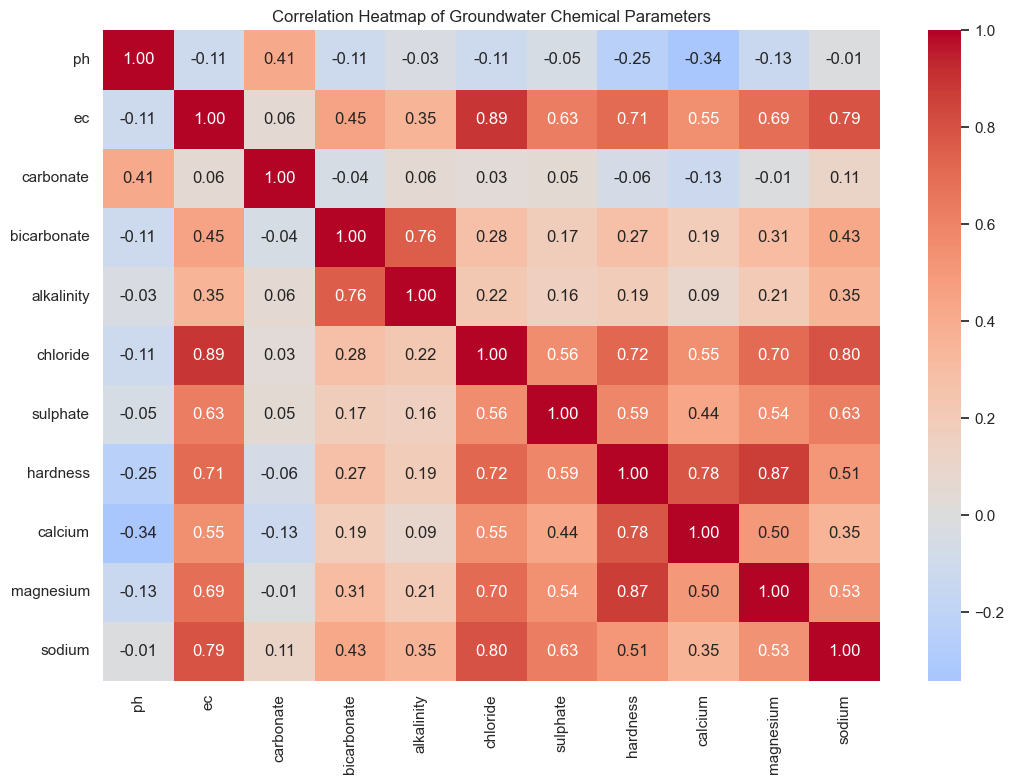

In [7]:
plt.figure(figsize=(11, 8))
sns.heatmap(data[numeric_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Groundwater Chemical Parameters")
plt.tight_layout()
plt.show()

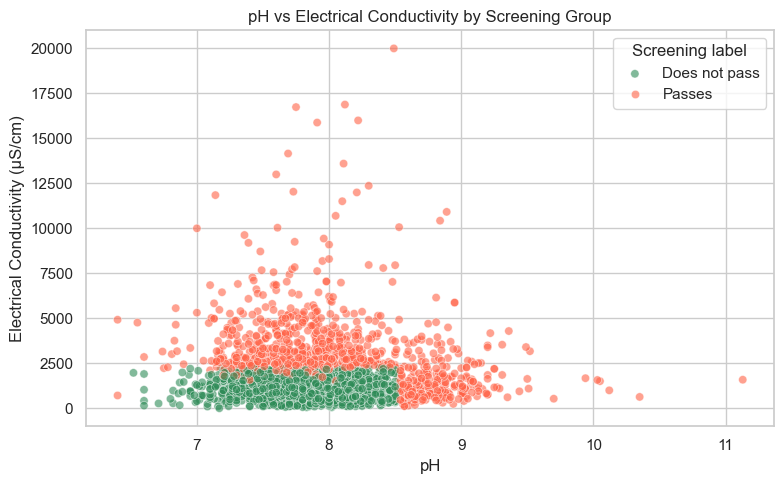

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data.sample(min(3000, len(data)), random_state=42),
    x="ph", y="ec", hue="is_potable", alpha=0.6,
    palette={0: "tomato", 1: "seagreen"}
)
plt.title("pH vs Electrical Conductivity by Screening Group")
plt.xlabel("pH")
plt.ylabel("Electrical Conductivity (μS/cm)")
plt.legend(title="Screening label", labels=["Does not pass", "Passes"])
plt.tight_layout()
plt.show()

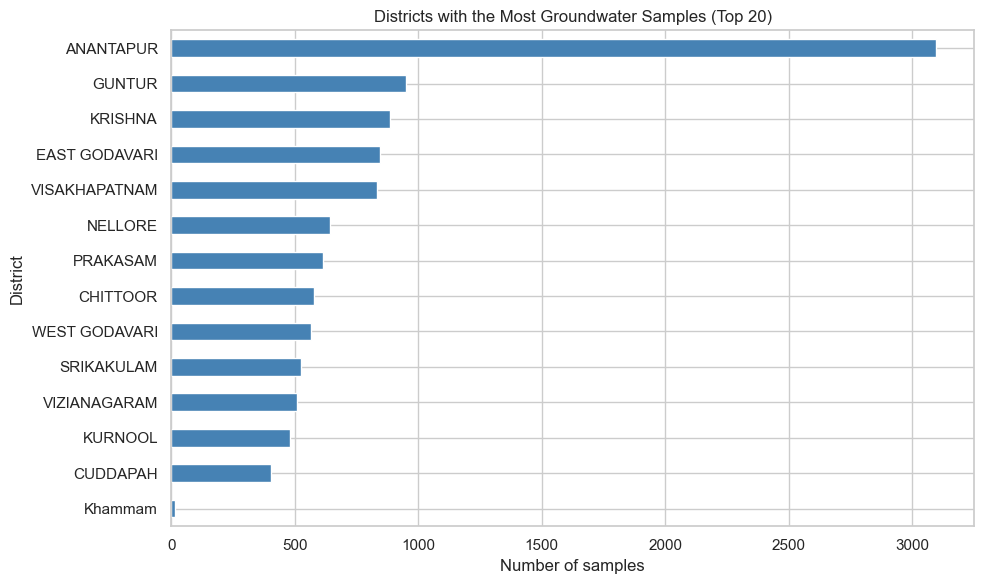

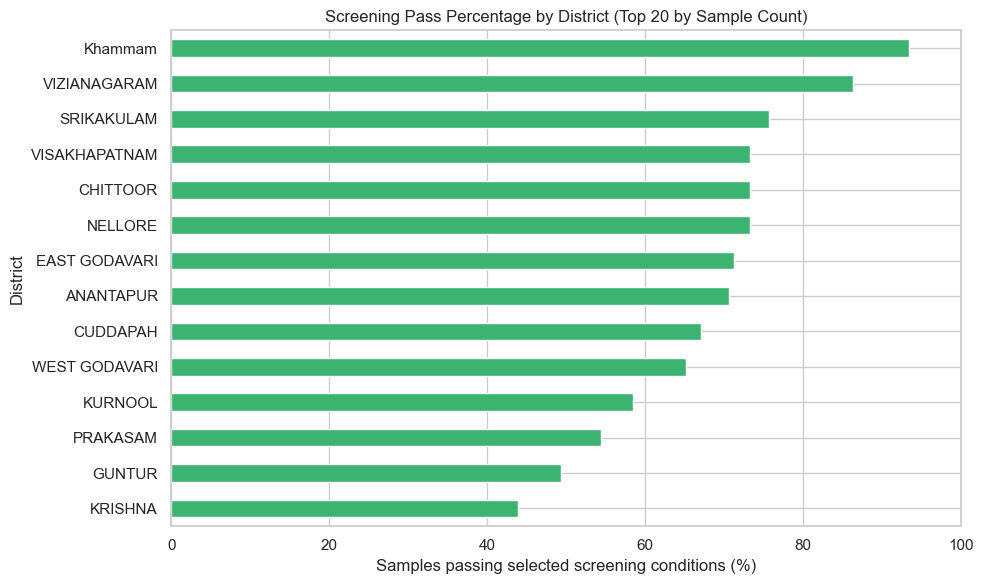

In [9]:
district_counts = data["district"].value_counts().head(20)

plt.figure(figsize=(10, 6))
district_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Districts with the Most Groundwater Samples (Top 20)")
plt.xlabel("Number of samples")
plt.ylabel("District")
plt.tight_layout()
plt.show()

district_screening = data.groupby("district")["is_potable"].mean().mul(100).sort_values(ascending=False)
district_screening = district_screening.loc[data["district"].value_counts().index]
district_screening = district_screening.head(20).sort_values()

plt.figure(figsize=(10, 6))
district_screening.plot(kind="barh", color="mediumseagreen")
plt.title("Screening Pass Percentage by District (Top 20 by Sample Count)")
plt.xlabel("Samples passing selected screening conditions (%)")
plt.ylabel("District")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [10]:
features = [
    "carbonate", "bicarbonate", "alkalinity",
    "calcium", "magnesium", "sodium"
]

X = data[features]
y = data["is_potable"]

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Predictor columns:", features)

Training samples: 8760
Testing samples: 2190
Predictor columns: ['carbonate', 'bicarbonate', 'alkalinity', 'calcium', 'magnesium', 'sodium']


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
nb_pred = nb.predict(X_test_scaled)

dt = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight="balanced")
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

rf = RandomForestClassifier(
    n_estimators=200, max_depth=8, random_state=42,
    class_weight="balanced"
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("All five models have been trained.")

All five models have been trained.


In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report
)

results_table = pd.DataFrame({
    "Model": ["Logistic Regression", "K-Nearest Neighbors", "Naive Bayes", "Decision Tree", "Random Forest"],
    "Accuracy (%)": [
        accuracy_score(y_test, lr_pred) * 100,
        accuracy_score(y_test, knn_pred) * 100,
        accuracy_score(y_test, nb_pred) * 100,
        accuracy_score(y_test, dt_pred) * 100,
        accuracy_score(y_test, rf_pred) * 100
    ],
    "Precision": [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, nb_pred, zero_division=0),
        precision_score(y_test, dt_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, nb_pred, zero_division=0),
        recall_score(y_test, dt_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, nb_pred, zero_division=0),
        f1_score(y_test, dt_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, lr_pred),
        balanced_accuracy_score(y_test, knn_pred),
        balanced_accuracy_score(y_test, nb_pred),
        balanced_accuracy_score(y_test, dt_pred),
        balanced_accuracy_score(y_test, rf_pred)
    ]
})

results_table = results_table.round(4)
display(results_table.sort_values("F1-Score", ascending=False))

,Model,Accuracy (%),Precision,Recall,F1-Score,Balanced Accuracy
1,K-Nearest Neighbors,87.0320,0.8696,0.9463,0.9063,0.8336
4,Random Forest,86.7580,0.8910,0.9118,0.9013,0.8462
2,Naive Bayes,84.7489,0.8481,0.9380,0.8908,0.8037
3,Decision Tree,84.3379,0.8764,0.8891,0.8827,0.8213
0,Logistic Regression,82.6484,0.8681,0.8705,0.8693,0.8052


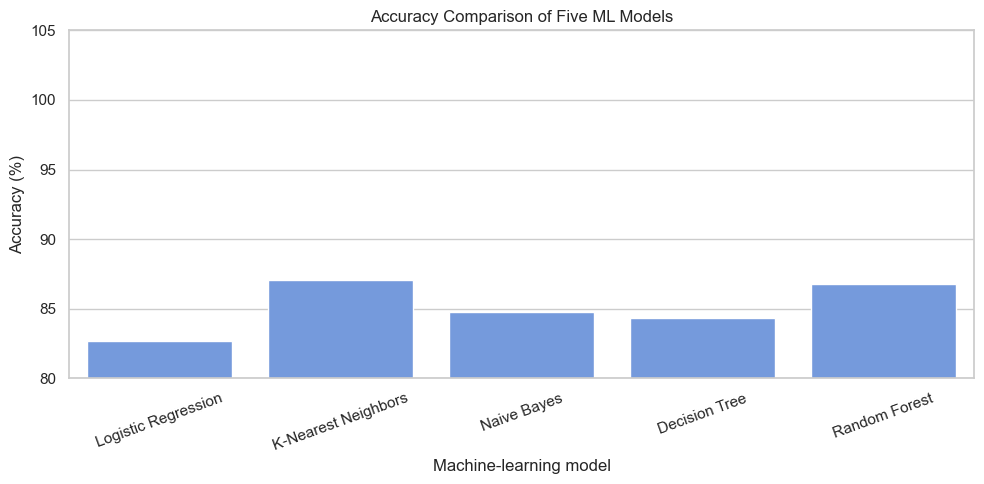

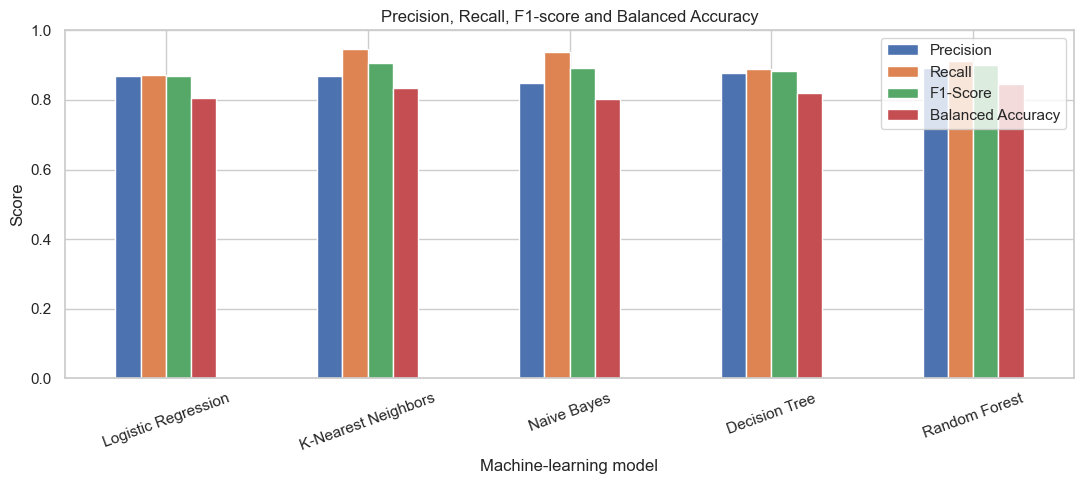

In [17]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_table, x="Model", y="Accuracy (%)", color="cornflowerblue")
plt.title("Accuracy Comparison of Five ML Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine-learning model")
plt.xticks(rotation=20)
plt.ylim(80, 105)
plt.tight_layout()
plt.show()

metric_comparison = results_table.set_index("Model")[["Precision", "Recall", "F1-Score", "Balanced Accuracy"]]
metric_comparison.plot(kind="bar", figsize=(11, 5))
plt.title("Precision, Recall, F1-score and Balanced Accuracy")
plt.ylabel("Score")
plt.xlabel("Machine-learning model")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Best model by test F1-score: K-Nearest Neighbors


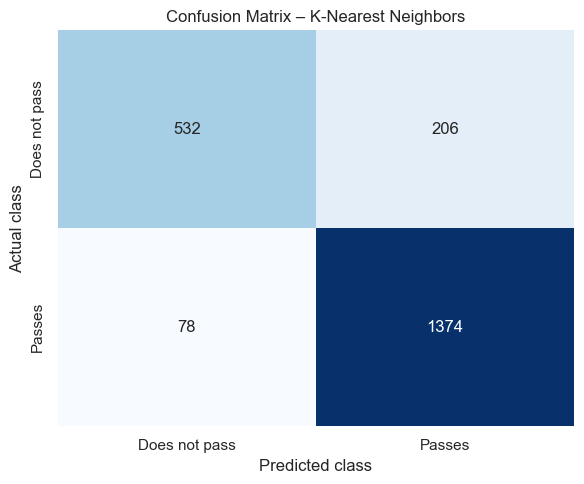

                         precision    recall  f1-score   support

Does not pass screening       0.87      0.72      0.79       738
       Passes screening       0.87      0.95      0.91      1452

               accuracy                           0.87      2190
              macro avg       0.87      0.83      0.85      2190
           weighted avg       0.87      0.87      0.87      2190



In [14]:
best_model_name = results_table.sort_values("F1-Score", ascending=False).iloc[0]["Model"]
print("Best model by test F1-score:", best_model_name)

from sklearn.metrics import confusion_matrix

if best_model_name == "Logistic Regression":
    best_pred = lr_pred
elif best_model_name == "K-Nearest Neighbors":
    best_pred = knn_pred
elif best_model_name == "Naive Bayes":
    best_pred = nb_pred
elif best_model_name == "Decision Tree":
    best_pred = dt_pred
else:
    best_pred = rf_pred

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Does not pass", "Passes"],
    yticklabels=["Does not pass", "Passes"]
)
plt.title("Confusion Matrix – " + best_model_name)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, best_pred,
    target_names=["Does not pass screening", "Passes screening"],
    zero_division=0
))

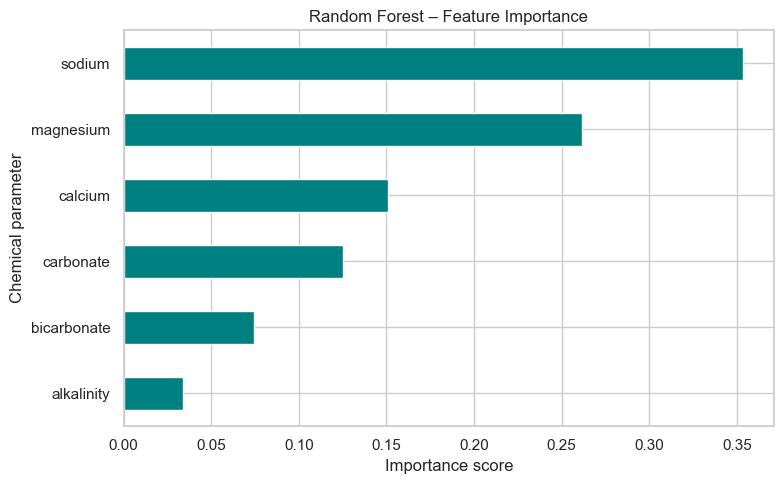

,Importance
sodium,0.353569
magnesium,0.261649
calcium,0.151054
carbonate,0.125497
bicarbonate,0.074491
alkalinity,0.033740


In [15]:
importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="teal")
plt.title("Random Forest – Feature Importance")
plt.xlabel("Importance score")
plt.ylabel("Chemical parameter")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("Importance"))

In [16]:
print("GROUNDWATER QUALITY ASSESSMENT – PROJECT SUMMARY")
print("Original records:", len(df))
print("Records after cleaning:", len(data))
print("Number of chemical parameters analyzed:", len(numeric_columns))
print("Number of ML predictor parameters:", len(features))
print("Best model by test F1-score:", best_model_name)
print("\nReminder: The target is a rule-based screening label, not a laboratory-confirmed potability result.")

GROUNDWATER QUALITY ASSESSMENT – PROJECT SUMMARY
Original records: 10950
Records after cleaning: 10950
Number of chemical parameters analyzed: 11
Number of ML predictor parameters: 6
Best model by test F1-score: K-Nearest Neighbors

Reminder: The target is a rule-based screening label, not a laboratory-confirmed potability result.
